# 5. Neural Networks

## 5.1 Feed-forward Network Functions

$$
\begin{align}
y(x,w) &= f\left(\sum_{j=1}^{M} w_j \phi_{j}(x) \right)\newline
\end{align}
$$

where $f(\cdot)$ is nonlinear function and It is identity for regression.

$$
\underbrace{a_j}_{\text{activation}} =
\sum_{i=1}^D \underbrace{w_{ji}^{(1)}}_{\text{weight}} x_i
+
\underbrace{w_{j0}^{(1)}}_{\text{bias}}
$$

where $j=1,\dots,M$ and superscript $(1)$ indicates the corresponding parameters in the first layer.

$$
z_j = h\left(a_j\right)
$$

The second layer,

$$
a_k = \sum_{j=1}^M w_{ki}^{(2)}z_j + w_{k0}^{(2)}
$$

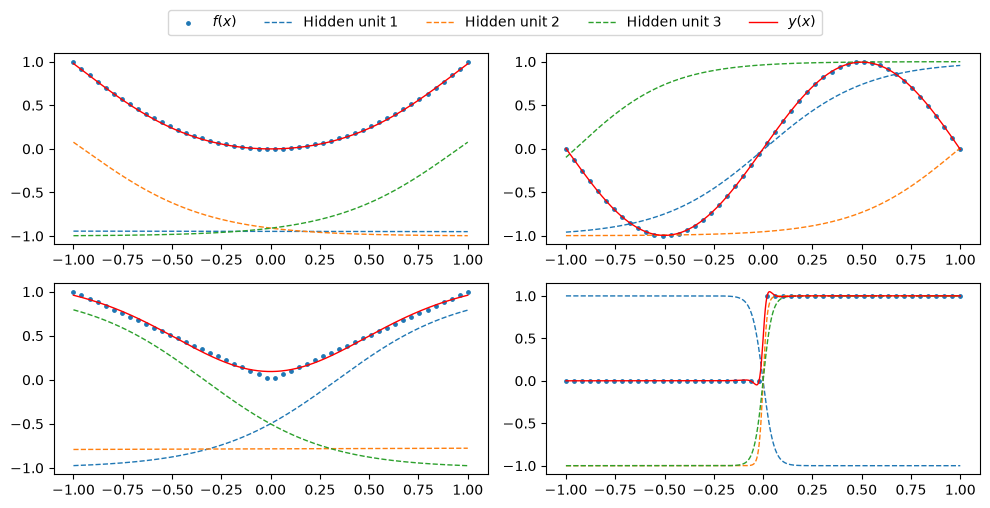

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from prml.nn.network import NeuralNetwork


def create_toy_data(func, n=50):
    x = np.linspace(-1, 1, n)[:, None]
    return x, func(x)


def sinusoidal(x):
    return np.sin(np.pi * x)


def heaviside(x):
    return 0.5 * (np.sign(x) + 1)


func_list = [np.square, sinusoidal, np.abs, heaviside]
# More iteration for complex function to fit correctly
n_iters = [1000, 1000, 1000, 10000]

x = np.linspace(-1, 1, 1000)[:, None]
x_test = torch.tensor(x, dtype=torch.float32)

fig, axes = plt.subplots(2, 2, figsize=(10, 5))

for ax, func, n_iter in zip(axes.flat, func_list, n_iters):
    # Generate training data
    x_train, y_train = create_toy_data(func)

    x_train = torch.tensor(x_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)

    # Initialize and train model
    model = NeuralNetwork(1, 3, 1)
    model.fit(x_train, y_train, n_iter=n_iter)

    # Predictions
    y_pred = model.predict(x_test).numpy()
    hidden_outputs = model.hidden_outputs(x_test).numpy()

    # Plot training data
    ax.scatter(x_train.numpy(), y_train.numpy(), s=6, label=r"$f(x)$")

    # Plot hidden unit outputs
    for j in range(3):
        ax.plot(
            x, hidden_outputs[:, j], "--", linewidth=1, label=rf"Hidden unit {j + 1}"
        )

    # Plot network output
    ax.plot(x, y_pred, "r", linewidth=1, label=r"$y(x)$")

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=5,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Hidden layer output can change significantly